# 567. Permutation in String
**Difficulty:** 🟡 Medium · **Topic:** Sliding Window · **Pattern:** [Fixed Window](README.md) · **LeetCode:** https://leetcode.com/problems/permutation-in-string/

## 💡 Concepts

**Core concept(s):** **fixed-size sliding window** + **letter counts**.

**Why it applies here:**
- A permutation of `s1` has exactly `len(s1)` letters, so every candidate in `s2` is a substring of that **one fixed length** `k`.
- Two strings are permutations of each other exactly when they have the **same count of every letter**. Order doesn't matter, counts do.
- Neighbouring windows share `k - 1` letters: moving one step right adds one letter and drops one letter. So the counts can be **updated**, not rebuilt.

**Key intuition:**
- Slide a window of width `k` across `s2`.
- Keep a count of the letters inside it: `+1` for the letter that enters on the right, `-1` for the letter that leaves on the left.
- When the window's counts equal `s1`'s counts, that window is a permutation of `s1`.

---

### 📚 What is a Sliding Window (fixed size)?
- A **window** is a contiguous slice `arr[l..r]` of an array or string.
- A **fixed-size** window always holds exactly `k` elements: when element `r` enters on the right, element `r - k` leaves on the left.
- Instead of recomputing something about each window from scratch (`O(k)` per window), you keep a running summary (sum, counts, max) and update it with the one element in and the one element out.
- **Complexity:** `n - k + 1` windows, `O(1)` update each → **O(n)** total instead of `O(n·k)`.
- **In Python:** just an index `r` in a `for` loop; the left edge is `r - k + 1`.

### 📚 What is a Frequency Count (hash map / count array)?
- A **frequency count** maps each item to how many times it appears.
- A **hash map** (Python `dict`, or `collections.Counter`) hashes each key to a slot, so increment and lookup are **O(1) on average**.
- When the keys are just the 26 lowercase letters, a plain **list of 26 ints** does the same job: letter `c` lives at index `ord(c) - ord('a')`.
- Comparing two 26-slot lists is **26 steps** — a constant, so `O(1)` no matter how long the strings are.
- **In Python:** `collections.Counter(s)` for a dict of counts; `[0] * 26` for the array version.

### 📚 What is Sorting (as a fingerprint)?
- Sorting puts letters in order, so any two permutations of the same letters sort to the **same string**: `sorted("ba") == sorted("ab")`.
- It costs **O(m log m)** for `m` letters — fine once, expensive if you do it for every window.
- **In Python:** `sorted(s)` returns a sorted list of characters.

---

**Prerequisite knowledge:**
- String slicing `s[i:j]` copies `j - i` characters (`O(j - i)`).
- `ord(c)` turns a character into its code point.

## 📝 Problem

Given two strings `s1` and `s2`, return `True` if `s2` contains a **permutation** of `s1` as a substring. In other words: some contiguous block of `s2` uses exactly the letters of `s1`, each the same number of times, in any order.

**Example 1**
```
s1 = "ab", s2 = "eidbaooo"  ->  True
         e i d [b a] o o o      "ba" is a permutation of "ab"
```

**Example 2**
```
s1 = "ab", s2 = "eidboaoo"  ->  False
         no block of 2 letters in s2 is {a, b}  ("bo", "oa" are close but wrong)
```

**Constraints:** `1 <= len(s1), len(s2) <= 10^4`; both strings contain lowercase English letters only.

> Three approaches: sort every window (`O(n·k log k)`), count every window from scratch (`O(n·k)`), and the fixed sliding window that updates the counts in `O(1)` per step (`O(n)`). Here `n = len(s2)` and `k = len(s1)`.

In [1]:
from typing import List
from collections import Counter
import random

### Approach 1 — Brute Force: sort every window

**Idea:**
1. Sort `s1` once: that is the fingerprint every permutation of `s1` shares.
2. For every start `l`, take the window `s2[l : l + k]`, sort it, and compare with the fingerprint.
3. The first match means a permutation is present.

**Time complexity:** `O((n - k + 1) · k log k)` — up to `n` windows, and each one is copied and sorted.

**Space complexity:** `O(k)` — the sorted copy of one window.

In [2]:
def check_inclusion_sort(s1: str, s2: str) -> bool:
    k = len(s1)
    target = sorted(s1)                        # every permutation of s1 sorts to this
    for l in range(len(s2) - k + 1):           # every window start (no windows if k > len(s2))
        if sorted(s2[l:l + k]) == target:      # copy + sort the whole window: O(k log k)
            return True
    return False

### Approach 2 — Better: count every window from scratch

**Idea:**
- Sorting is more than we need: a permutation only has to match the **letter counts**.
- Build `Counter(s1)` once, then for every window build `Counter(window)` and compare.
- Still wasteful: neighbouring windows share `k - 1` letters, yet each count is rebuilt from zero.

**Time complexity:** `O((n - k + 1) · k)` — every window is copied and counted letter by letter.

**Space complexity:** `O(1)` beyond the window copy — at most 26 keys per counter (`O(k)` for the slice).

In [3]:
def check_inclusion_count(s1: str, s2: str) -> bool:
    k = len(s1)
    need = Counter(s1)                         # letter -> count for s1
    for l in range(len(s2) - k + 1):
        if Counter(s2[l:l + k]) == need:       # rebuilt from scratch: O(k) per window
            return True
    return False

### Approach 3 — Fixed Sliding Window with count arrays (optimal · pattern template)

**Idea:** the [Fixed Window](README.md) template: one loop, one element in, one element out, check when the window is full.
1. `need` = letter counts of `s1` (26 slots). `window` = letter counts of the current window of `s2`.
2. For each `r`: letter `s2[r]` **enters** (`+1`).
3. Once `r >= k`, letter `s2[r - k]` **leaves** (`-1`), so the window always holds exactly `k` letters.
4. Once `r >= k - 1` the window is full: if `window == need`, it is a permutation of `s1`.

**Time complexity:** `O(n)` — each step does two `O(1)` count updates and one 26-slot compare (constant).

**Space complexity:** `O(1)` — two arrays of 26 ints, whatever the input size.

In [4]:
def check_inclusion_window(s1: str, s2: str) -> bool:
    k = len(s1)
    need = [0] * 26                                  # letter counts of s1 (the target)
    for c in s1:
        need[ord(c) - ord('a')] += 1
    window = [0] * 26                                # letter counts of the current window of s2
    for r in range(len(s2)):
        window[ord(s2[r]) - ord('a')] += 1           # 1) s2[r] enters on the right
        if r >= k:
            window[ord(s2[r - k]) - ord('a')] -= 1   # 2) s2[r-k] leaves on the left: size stays k
        if r >= k - 1 and window == need:            # 3) full window with s1's counts = permutation
            return True
    return False                                     # also covers k > len(s2): never full

In [5]:
# Correctness check
tests = [
    ("ab",  "eidbaooo", True),    # LeetCode example 1: "ba" at index 3
    ("ab",  "eidboaoo", False),   # LeetCode example 2
    ("adc", "dcda",     True),    # "cda" at the end
    ("a",   "a",        True),    # k == n
    ("abc", "ab",       False),   # s1 longer than s2: no window fits
    ("aab", "abbba",    False),   # same letters {a, b}, but no window has two a's: counts matter
    ("hello", "ooolleoooleh", False),
]
for s1, s2, exp in tests:
    a, b, c = check_inclusion_sort(s1, s2), check_inclusion_count(s1, s2), check_inclusion_window(s1, s2)
    print(f"s1={s1!r:8} s2={s2!r:15} -> {c}")
    assert a == b == c == exp, f"mismatch on {s1!r}, {s2!r}: sort={a} count={b} window={c}"

# Randomised cross-check on a small alphabet, so matches actually happen
rng = random.Random(567)
for _ in range(500):
    s1 = "".join(rng.choice("abc") for _ in range(rng.randint(1, 4)))
    s2 = "".join(rng.choice("abc") for _ in range(rng.randint(1, 12)))
    assert check_inclusion_sort(s1, s2) == check_inclusion_count(s1, s2) == check_inclusion_window(s1, s2), (s1, s2)
print("500 random pairs: all three approaches agree")

print("\nAll tests passed")

s1='ab'     s2='eidbaooo'      -> True
s1='ab'     s2='eidboaoo'      -> False
s1='adc'    s2='dcda'          -> True
s1='a'      s2='a'             -> True
s1='abc'    s2='ab'            -> False
s1='aab'    s2='abbba'         -> False
s1='hello'  s2='ooolleoooleh'  -> False
500 random pairs: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** |
| `O(n²)`       | ≈ **4×** |

The brute force and the per-window counter only look slow when the window is **long**, so the worst case sets `k = n/2` (then `n·k` grows like `n²`). `s2` is random letters `a`–`y` and `s1` contains a `z`, so no window ever matches and nobody exits early. Expect ≈4× (or a bit more) for Approaches 1–2 and ≈2× for the sliding window.


sort O(n*k log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |      14.35 |           n/a


     2000 |      60.44 |         4.21x

     4000 |     252.98 |         4.19x


     8000 |    1019.33 |         4.03x

count O(n*k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       5.08 |           n/a
     2000 |      18.74 |         3.69x


     4000 |      74.48 |         3.97x


     8000 |     291.98 |         3.92x

window O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     1000 |       0.10 |           n/a
     2000 |       0.19 |         1.99x
     4000 |       0.37 |         1.89x
     8000 |       0.76 |         2.08x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


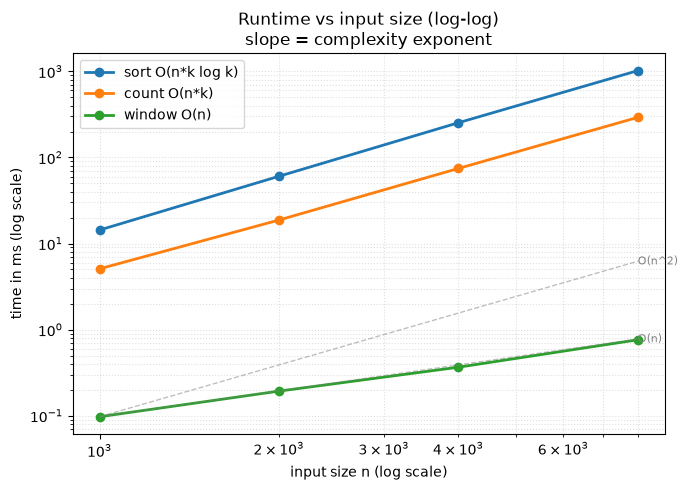

{'sort O(n*k log k)': [14.345709001645446,
  60.43874996248633,
  252.97654198948294,
  1019.3319169338793],
 'count O(n*k)': [5.0825419602915645,
  18.74487497843802,
  74.47600003797561,
  291.9757911004126],
 'window O(n)': [0.09724998380988836,
  0.1930419821292162,
  0.36575004924088717,
  0.7616250077262521]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    rng = random.Random(n)
    s2 = "".join(rng.choice("abcdefghijklmnopqrstuvwxy") for _ in range(n))   # no 'z' anywhere
    s1 = "z" + "".join(rng.choice("abcdefghijklmnopqrstuvwxy") for _ in range(n // 2 - 1))
    return (s1, s2)                       # k = n/2 and no window can match: no early exit
solutions = {
    "sort O(n*k log k)": check_inclusion_sort,
    "count O(n*k)": check_inclusion_count,
    "window O(n)": check_inclusion_window,
}
sizes = [1000, 2000, 4000, 8000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Fixed Window](README.md) — every candidate has length `len(s1)`, so a window of that fixed width slides across `s2`; one letter enters, one leaves, and a 26-slot count compare checks each full window.
- **"Permutation / anagram of X inside Y" → compare letter counts, not orderings.** Counts are order-free and cheap to update; sorting is order-free but must be redone per window.
- **Update, don't rebuild:** neighbouring windows differ by two letters, so `+1` / `-1` turns an `O(k)` recount into `O(1)` work.
- **Signal:** "permutation / anagram of `p` as a substring", "every substring of length `k`", "window of size `k`".
- **Related problems:** Find All Anagrams in a String (collect every matching start instead of returning `True`), Maximum Average Subarray I (running sum in a fixed window), Sliding Window Maximum (same window, a monotonic deque as the summary).
- **Common pitfalls:**
  1. Removing the wrong letter: the one leaving is `s2[r - k]`, not `s2[r - k + 1]` (that one is still inside).
  2. Checking before the window is full (`r < k - 1`): a partial window can't be a permutation.
  3. Comparing the *set* of letters instead of the counts: `"aab"` vs `"abb"`.
  4. Forgetting `len(s1) > len(s2)`: no window fits, the answer is `False`.